# Balancedness of a dendrogram

`ac.balancedness(Z)` describes how evenly a dendrogram splits its leaves, level by level. Every
distinct merge height defines a level, a partition of the `n` leaves into `k` clusters. Each
level is compared with the most even split (`H_max`) and the most skewed one (`H_min`, `k - 1`
singletons):

`B = mean over levels of (H - H_min) / (H_max - H_min)`, with `H` the entropy of the cluster
sizes. `B = 1` when every level is as even as possible, `B = 0` for a caterpillar tree.

This notebook needs `pip install adaptive_cut networkx matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from scipy.cluster.hierarchy import linkage

import adaptive_cut as ac

## Extreme trees

In [2]:
def caterpillar(n):
    """Each merge adds one leaf."""
    Z, node = [], 0
    for i in range(1, n):
        Z.append([node, i, i, i + 1])
        node = n + i - 1
    return np.array(Z, dtype=float)


def balanced(depth):
    """Perfectly balanced tree, merging in waves."""
    n = 2**depth
    Z, current, nxt, h = [], list(range(n)), n, 1.0
    while len(current) > 1:
        new = []
        for a, b in zip(current[::2], current[1::2]):
            Z.append([a, b, h, 0])
            new.append(nxt)
            nxt += 1
        current, h = new, h + 1
    Z = np.array(Z, dtype=float)
    size = np.ones(2 * n - 1)
    for i, (a, b) in enumerate(Z[:, :2].astype(int)):
        size[n + i] = size[a] + size[b]
    Z[:, 3] = size[n:]
    return Z


print("caterpillar, 32 leaves:", ac.balancedness(caterpillar(32)))
print("balanced, 32 leaves:   ", ac.balancedness(balanced(5)))
rng = np.random.default_rng(0)
print(
    "random points, ward:   ",
    round(ac.balancedness(linkage(rng.standard_normal((300, 2)), "ward")), 2),
)
print(
    "random points, single: ",
    round(ac.balancedness(linkage(rng.standard_normal((300, 2)), "single")), 2),
)

caterpillar, 32 leaves: 0.0
balanced, 32 leaves:    1.0
random points, ward:    0.94
random points, single:  0.64


## Level by level

`balancedness(Z, return_levels=True)` also returns the entropy of every level with its bounds.
Here for the edge tree of the karate club.

B = 0.63 over 21 informative levels


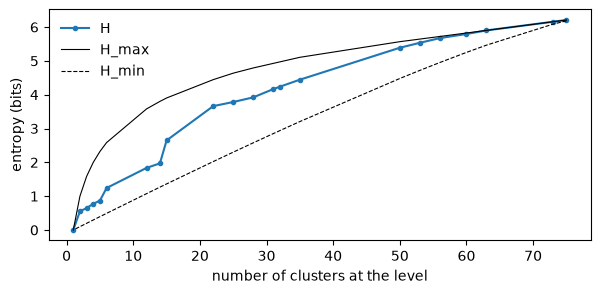

In [3]:
r = ac.link_communities(nx.karate_club_graph(), adaptive=False)
B, levels = ac.balancedness(r.Z, return_levels=True)
print(f"B = {B:.2f} over {np.isfinite(levels.ratio).sum()} informative levels")

plt.figure(figsize=(7, 3))
plt.plot(levels.n_clusters, levels.entropy, ".-", label="H")
plt.plot(levels.n_clusters, levels.entropy_max, "k-", lw=0.8, label="H_max")
plt.plot(levels.n_clusters, levels.entropy_min, "k--", lw=0.8, label="H_min")
plt.xlabel("number of clusters at the level")
plt.ylabel("entropy (bits)")
plt.legend(frameon=False);